# 🧁 PyTorch ile Özel Görsel Veri Seti (Custom Dataset) & Desert101 Sınıflandırma

Bu notebook'ta, hazır veri setlerinden (CIFAR-10, MNIST vb.) çıkarak **kendi özel görsel veri setimizi (Custom Dataset)** nasıl yükleyeceğimizi, eğiteceğimizi ve canlıda test edeceğimizi uçtan uca öğreniyoruz.

Projede **Desert101** (Food-101 veri setinden 4 tatlı türü: `baklava`, `cannoli`, `cup_cakes`, `donuts`) kullanılmaktadır.

---

### 🗺️ İçindekiler
1. [Gerekli Kütüphanelerin Yüklenmesi & Cihaz Ayarı](#1-gerekli-kütüphanelerin-yüklenmesi--cihaz-ayarı)
2. [Özel Veri Seti Klasör Yapısı & Keşifsel Analiz (EDA)](#2-özel-veri-seti-klasör-yapısı--keşifsel-analiz-eda)
3. [Görsel Dönüşümleri (Transforms) & `ImageFolder` ile Veri Yükleme](#3-görsel-dönüşümleri-transforms--imagefolder-ile-veri-yükleme)
4. [DataLoader Kurulumu & Batch Boyutu](#4-dataloader-kurulumu--batch-boyutu)
5. [TinyVGG Evrişimli Sinir Ağı (`DesertClassifier`) Mimarisi](#5-tinyvgg-evrişimli-sinir-ağı-desertclassifier-mimarisi)
6. [`torchinfo` ile Model Özeti & Boyut Röntgeni](#6-torchinfo-ile-model-özeti--boyut-röntgeni)
7. [Modüler Eğitim Mimarisi: `train_step()`, `test_step()` ve `train()`](#7-modüler-eğitim-mimarisi-train_step-test_step-ve-train)
8. [Model 0: Temel Model Eğitimi (Baseline Model - 10 Epoch)](#8-model-0-temel-model-eğitimi-baseline-model---10-epoch)
9. [Kayıp Eğrileri & Rastgele Test Tahminleri](#9-kayıp-eğrileri--rastgele-test-tahminleri)
10. [Canlı Çıkarım (Inference): İnternetten İndirilen Tekil Görselle Tahmin](#10-canlı-çıkarım-inference-internetten-indirilen-tekil-görselle-tahmin)
11. [ÖDEV & BİLİMSEL DENEY: Model 1 (Veri Artırma / Augmentation & 20 Epoch)](#11-ödev--bilimsel-deney-model-1-veri-artırma--augmentation--20-epoch)
12. [Büyük Karşılaştırma & Overfitting Analizi](#12-büyük-karşılaştırma--overfitting-analizi)


## 1. Gerekli Kütüphanelerin Yüklenmesi & Cihaz Ayarı


In [1]:
import torch
from torch import nn
import numpy as np

In [2]:
from pathlib import Path
data_path = Path("data/")
image_path = data_path / "desert101"

In [3]:
image_path

PosixPath('data/desert101')

## 2. Özel Veri Seti Klasör Yapısı & Keşifsel Analiz (EDA)

Gerçek dünya projelerinde görseller genellikle standart bir klasör hiyerarşisiyle tutulur:
```
data/
  train/
    baklava/   (örnek1.jpg, örnek2.jpg...)
    cannoli/
    cup_cakes/
    donuts/
  test/
    baklava/
    cannoli/
    ...
```
Aşağıdaki yardımcı fonksiyon bu klasör yapısındaki alt dizin ve dosya sayılarını listeler:


In [4]:
import os

In [5]:
def check_data(dir_path):
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"Dizin sayısı: {len(dirnames)} and {len(filenames)} images in '{dirpath}'.")

In [6]:
check_data(image_path)

# of directories: 2 and 1 images in 'data/desert101'.
# of directories: 4 and 1 images in 'data/desert101/test'.
# of directories: 0 and 20 images in 'data/desert101/test/cup_cakes'.
# of directories: 0 and 20 images in 'data/desert101/test/donuts'.
# of directories: 0 and 20 images in 'data/desert101/test/cannoli'.
# of directories: 0 and 20 images in 'data/desert101/test/baklava'.
# of directories: 4 and 1 images in 'data/desert101/train'.
# of directories: 0 and 80 images in 'data/desert101/train/cup_cakes'.
# of directories: 0 and 80 images in 'data/desert101/train/donuts'.
# of directories: 0 and 80 images in 'data/desert101/train/cannoli'.
# of directories: 0 and 80 images in 'data/desert101/train/baklava'.


In [7]:
train_dir = image_path / "train"
test_dir = image_path / "test"

In [8]:
train_dir

PosixPath('data/desert101/train')

In [9]:
test_dir

PosixPath('data/desert101/test')

### Rastgele Görsel İnceleme
Disk üzerindeki orijinal görsellerden rastgele bir tanesini açıp çözünürlüğünü ve piksel yapısını inceliyoruz:


In [10]:
# Rastgele bir görsel seçip ekranda gösterelim
import random
from PIL import Image

random.seed(42) 

# 1. Tüm görsel yollarını alıyoruz 
image_path_list = list(image_path.glob("*/*/*.jpg"))

# 2. Rastgele bir görsel yolu seçiyoruz
random_image_path = random.choice(image_path_list)

# 3. Sınıf adını görselin bulunduğu klasörün isminden elde ediyoruz
image_class = random_image_path.parent.stem

# 4. Görseli açıyoruz
img = Image.open(random_image_path)

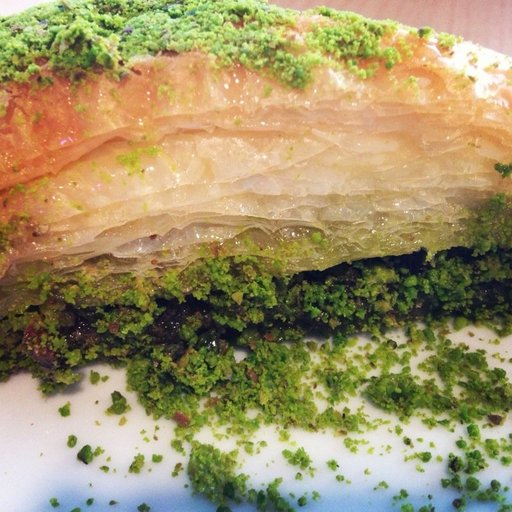

In [11]:
img

## 3. Görsel Dönüşümleri (Transforms) & `ImageFolder` ile Veri Yükleme

Farklı çözünürlüklerdeki fotoğrafları standart bir CNN girdisine dönüştürmek için:
1. **`Resize((64, 64))`:** Tüm görseller $64 \times 64$ piksele eşitlenir.
2. **`RandomHorizontalFlip(p=0.4)`:** Görseller %40 olasılıkla yatay aynalanır.
3. **`ToTensor()`:** Pikseller `[0.0, 1.0]` aralığında `[C, H, W]` tensörüne çevrilir.
4. **`datasets.ImageFolder`:** Klasör isimlerini otomatik olarak $0, 1, 2, 3$ şeklinde sınıf etiketlerine dönüştürür.


In [12]:
# Özel Veri Seti (Custom Dataset) oluşturma aşamasına geçiyoruz


In [13]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [14]:
# Görsel boyutlandırma ve dönüştürme hattı (Transforms)


In [15]:

data_transform = transforms.Compose([
    # Görselleri 64x64 piksele standartlaştırıyoruz
    transforms.Resize(size=(64, 64)), # hedef piksel boyutu (64x64)
    # %40 ihtimalle yatay çevirme (veri artırma)
    transforms.RandomHorizontalFlip(p=0.4), # çevrilme olasılığı %40
    # Veri Artırma (Data Augmentation)
    transforms.TrivialAugmentWide(),
    # Görseli PyTorch tensörüne dönüştür
    transforms.ToTensor() 
])

In [16]:
# torchvision.datasets.ImageFolder ile klasör yapısını otomatik olarak etiketli veri setine dönüştürüyoruz

from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir, # hedef görsel klasörü
                                  transform=data_transform,  
                                  target_transform=None) # etiketler üzerinde dönüşüm (gerekirse)

test_data = datasets.ImageFolder(root=test_dir, 
                                 transform=data_transform)

In [17]:
train_data

Dataset ImageFolder
    Number of datapoints: 316
    Root location: data/desert101/train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.4)
               TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
               ToTensor()
           )

In [18]:
test_data

Dataset ImageFolder
    Number of datapoints: 77
    Root location: data/desert101/test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.4)
               TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
               ToTensor()
           )

In [19]:
class_names =train_data.classes

In [20]:
class_names

['baklava', 'cannoli', 'cup_cakes', 'donuts']

In [21]:
len(train_data), len(test_data)

(316, 77)

## 4. DataLoader Kurulumu & Batch Boyutu

Tüm veri setini tek seferde belleğe yüklemek yerine $32$'şerli paketlere (`batch_size=32`) bölüyoruz.  
İşlemci çekirdeklerinden (`os.cpu_count()`) tam verim alabilmek için `num_workers` parametresi kullanılır.


In [22]:
# Veri setini DataLoader'a vererek modele girecek mini-batch'lere bölüyoruz


In [23]:
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()
# Kullanılabilir CPU çekirdek sayısı

In [24]:
NUM_WORKERS

8

In [25]:
train_dataloader = DataLoader(dataset=train_data, 
                              batch_size=BATCH_SIZE, # mini-batch başına örnek sayısı
    num_workers=NUM_WORKERS # Veri yükleme için kullanılacak alt işlemci çekirdeği sayısı
                              shuffle=True) 

test_dataloader = DataLoader(dataset=test_data, 
                             batch_size=BATCH_SIZE, 
                             num_workers=NUM_WORKERS, 
                             shuffle=False)

In [26]:
# Veri hazır; şimdi CNN modelimizi tanımlıyoruz out

train_dataloader

In [27]:
train_dataloader.dataset[0][0]

tensor([[[0.1216, 0.1216, 0.1294,  ..., 0.1451, 0.1608, 0.1608],
         [0.1255, 0.1216, 0.1412,  ..., 0.1373, 0.1490, 0.1725],
         [0.1490, 0.1255, 0.1569,  ..., 0.1529, 0.1451, 0.1843],
         ...,
         [0.2157, 0.2235, 0.2275,  ..., 0.2667, 0.2627, 0.2588],
         [0.2235, 0.2196, 0.2157,  ..., 0.2706, 0.2667, 0.2588],
         [0.2235, 0.2314, 0.2275,  ..., 0.2588, 0.2627, 0.2549]],

        [[0.0863, 0.0824, 0.0941,  ..., 0.1137, 0.1294, 0.1294],
         [0.0941, 0.0902, 0.1098,  ..., 0.1059, 0.1216, 0.1412],
         [0.1098, 0.0902, 0.1216,  ..., 0.1176, 0.1176, 0.1569],
         ...,
         [0.1490, 0.1569, 0.1608,  ..., 0.2235, 0.2078, 0.1922],
         [0.1569, 0.1529, 0.1490,  ..., 0.2235, 0.2196, 0.1961],
         [0.1608, 0.1725, 0.1725,  ..., 0.2078, 0.2078, 0.1922]],

        [[0.0235, 0.0196, 0.0235,  ..., 0.0431, 0.0588, 0.0549],
         [0.0275, 0.0275, 0.0392,  ..., 0.0392, 0.0471, 0.0627],
         [0.0275, 0.0275, 0.0471,  ..., 0.0392, 0.0471, 0.

## 5. TinyVGG Evrişimli Sinir Ağı (`DesertClassifier`) Mimarisi

Modelimiz iki ardışık **Evrişim Bloğu (Convolutional Block)** ve bir **Sınıflandırıcı (Classifier)** katmanından oluşur:
- **Block 1:** $2 \times \text{Conv2d}(3 \to 32, \text{pad}=1) \to \text{ReLU} \to \text{MaxPool2d}(2) \implies [32, 32, 32]$
- **Block 2:** $2 \times \text{Conv2d}(32 \to 32, \text{pad}=1) \to \text{ReLU} \to \text{MaxPool2d}(2) \implies [32, 16, 16]$
- **Classifier:** $\text{Flatten} \to \text{Linear}(32 \times 16 \times 16 \to 4)$


In [28]:
class DesertClassifier(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, 
                      out_channels=hidden_units, 
                      kernel_size=3, 
                      stride=1, 
                      padding=1), 
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, 
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2) # varsayılan stride değeri kernel_size (2) ile aynıdır
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*16*16,
                      out_features=output_shape)
        )
    
    def forward(self, x: torch.Tensor):
        return self.classifier(self.conv_block_2(self.conv_block_1(x))) 

In [29]:
#torch.manual_seed(42)
model_0 = DesertClassifier(input_shape=3, # renk kanalı sayısı (RGB için 3) 
                  hidden_units=32, 
                  output_shape=len(train_data.classes))

In [30]:
len(class_names)

4

## 6. `torchinfo` ile Model Özeti & Boyut Röntgeni

`torchinfo.summary()` fonksiyonu, modele sahte bir girdi `[1, 3, 64, 64]` göndererek her katmandaki tensör boyut değişimlerini ve parametre sayılarını raporlar.

Burada en sondaki havuzlama katmanının çıktısının **$16 \times 16 \times 32 = 8192$** olduğunu doğruluyoruz:


In [31]:
!pip install torchinfo


In [32]:
# Model mimarisini ve katman boyutlarını özetleyen kütüphane

In [33]:
# Sınıflandırıcı giriş boyutunu (hidden_units * 16 * 16) buradan teyit ediyoruz layer
from torchinfo import summary


In [34]:
summary(model_0, input_size=[1, 3, 64, 64]) # örnek girdi tensörü ile test geçişi yap 

Layer (type:depth-idx)                   Output Shape              Param #
DesertClassifier                         [1, 4]                    --
├─Sequential: 1-1                        [1, 32, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 32, 64, 64]           896
│    └─ReLU: 2-2                         [1, 32, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 32, 64, 64]           9,248
│    └─ReLU: 2-4                         [1, 32, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 32, 32, 32]           --
├─Sequential: 1-2                        [1, 32, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 32, 32, 32]           9,248
│    └─ReLU: 2-7                         [1, 32, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 32, 32, 32]           9,248
│    └─ReLU: 2-9                         [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 32, 16, 16]           --
├─Seq

In [35]:
16 * 16 * 32

8192

## 7. Modüler Eğitim Mimarisi: `train_step()`, `test_step()` ve `train()`

Kodun yeniden kullanılabilirliğini (reusability) artırmak için eğitim döngüsünü 3 bağımsız fonksiyona bölüyoruz:
1. **`train_step()`:** Bir epoch içindeki eğitim batch'lerini işler, kayıp hesaplar, geriye yayılım yapar ve ağırlıkları günceller.
2. **`test_step()`:** `torch.inference_mode()` altında test batch'leri üzerinde doğruluk ve kayıp ölçer.
3. **`train()`:** Belirtilen epoch sayısı boyunca bu iki adımı yürütür, metrikleri sözlükte toplar ve ekrana yazdırır.


In [36]:
# Eğitim ve test adımlarını modüler fonksiyonlara dönüştürüyoruz


In [37]:
def train_step(model: torch.nn.Module, 
               dataloader: torch.utils.data.DataLoader, 
               loss_fn: torch.nn.Module, 
               optimizer: torch.optim.Optimizer):
    # Modeli eğitim moduna al
    model.train()
    
    # Kümülatif kayıp ve doğruluk sayaçlarını başlat
    train_loss, train_acc = 0, 0
    
    # Mini-batch'ler üzerinde döngü
    for batch, (X, y) in enumerate(dataloader):

        # 1. İleri Yayılım (Forward Pass)
        y_pred = model(X)

        # 2. Kaybı hesapla ve biriktir
        loss = loss_fn(y_pred, y)
        train_loss += loss.item() 

        # 3. Gradyanları sıfırla
        optimizer.zero_grad()

        # 4. Geriye yayılım (Backpropagation)
        loss.backward()

        # 5. Ağırlıkları güncelle
        optimizer.step()

        # Doğruluk metriğini hesapla
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y_pred)

    # Batch başına ortalama kayıp ve doğruluğu hesapla 
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc

In [38]:
def test_step(model: torch.nn.Module, 
              dataloader: torch.utils.data.DataLoader, 
              loss_fn: torch.nn.Module):
    # Modeli değerlendirme moduna al
    model.eval() 
    
    # Test kayıp ve doğruluk sayaçlarını başlat
    test_loss, test_acc = 0, 0
    
    # Gradyan takibini kapat (bellek tasarrufu)
    with torch.inference_mode():
        # Test batch'leri üzerinde döngü
        for batch, (X, y) in enumerate(dataloader):
    
            # 1. İleri Yayılım (Forward Pass)
            test_pred_logits = model(X)

            # 2. Test kaybını hesapla
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()
            
            # Test doğruluğunu hesapla
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))
            
    # Batch başına ortalama kayıp ve doğruluğu hesapla 
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

In [39]:
# train_step ve test_step'i birleştiren ana eğitim fonksiyonu
def train(model: torch.nn.Module, 
          train_dataloader: torch.utils.data.DataLoader, 
          test_dataloader: torch.utils.data.DataLoader, 
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):
    
    # Metrik sonuçları için boş sözlük
    results = {"train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }
    
    # Belirtilen epoch sayısı kadar eğitim ve test yap
    for epoch in range(epochs):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer)
        test_loss, test_acc = test_step(model=model,
            dataloader=test_dataloader,
            loss_fn=loss_fn)
        
        # Epoch sonuçlarını ekrana yazdır
        print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # Sonuç sözlüğünü güncelle
        # Değerleri float olarak sözlüğe kaydet
        results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc)
        results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)

    # Sonuç sözlüğünü döndür
    return results

## 8. Model 0: Temel Model Eğitimi (Baseline Model - 10 Epoch)

İlk temel modelimizi (`model_0`) 10 epoch boyunca eğitiyoruz:


In [40]:
# Set random seeds
#torch.manual_seed(42) 
#torch.cuda.manual_seed(42)

# Epoch sayısını belirle
NUM_EPOCHS = 10

# Model örneğini oluştur
model_0 = DesertClassifier(input_shape=3,
                  hidden_units=32, 
                  output_shape=len(train_data.classes))

# Kayıp fonksiyonu ve optimizasyon algoritmasını kur
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

# Temel modeli (model_0) eğit 
model_0_results = train(model=model_0, 
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader,
                        optimizer=optimizer,
                        loss_fn=loss_fn, 
                        epochs=NUM_EPOCHS)

Epoch: 1 | train_loss: 1.4007 | train_acc: 0.2112 | test_loss: 1.3891 | test_acc: 0.1875
Epoch: 2 | train_loss: 1.3881 | train_acc: 0.2437 | test_loss: 1.3900 | test_acc: 0.2396
Epoch: 3 | train_loss: 1.3870 | train_acc: 0.2723 | test_loss: 1.3871 | test_acc: 0.2917
Epoch: 4 | train_loss: 1.3823 | train_acc: 0.2799 | test_loss: 1.3926 | test_acc: 0.1771
Epoch: 5 | train_loss: 1.3847 | train_acc: 0.2964 | test_loss: 1.3899 | test_acc: 0.1875
Epoch: 6 | train_loss: 1.3472 | train_acc: 0.3504 | test_loss: 1.3195 | test_acc: 0.4030
Epoch: 7 | train_loss: 1.3512 | train_acc: 0.3942 | test_loss: 1.3497 | test_acc: 0.3534
Epoch: 8 | train_loss: 1.3113 | train_acc: 0.3897 | test_loss: 1.3379 | test_acc: 0.3213
Epoch: 9 | train_loss: 1.2865 | train_acc: 0.3937 | test_loss: 1.2910 | test_acc: 0.3998
Epoch: 10 | train_loss: 1.2202 | train_acc: 0.4268 | test_loss: 1.2640 | test_acc: 0.3534


In [41]:
model_0_results

{'train_loss': [1.400741493701935,
  1.3881004571914672,
  1.3870296955108643,
  1.3822565793991088,
  1.3846527457237243,
  1.3472428560256957,
  1.3512462854385376,
  1.3113106846809388,
  1.2865136742591858,
  1.220168364048004],
 'train_acc': [0.21116071428571428,
  0.24375,
  0.27232142857142855,
  0.2799107142857143,
  0.29642857142857143,
  0.35044642857142855,
  0.39419642857142856,
  0.38973214285714286,
  0.39375,
  0.4267857142857143],
 'test_loss': [1.3890957832336426,
  1.3899736404418945,
  1.3870715697606404,
  1.3925811847050984,
  1.3899421294530232,
  1.319502313931783,
  1.3496955235799153,
  1.337912122408549,
  1.2909515301386516,
  1.2639958063761394],
 'test_acc': [0.1875,
  0.23958333333333334,
  0.2916666666666667,
  0.17708333333333334,
  0.1875,
  0.4030448717948718,
  0.3533653846153846,
  0.3213141025641026,
  0.3998397435897436,
  0.3533653846153846]}

## 9. Kayıp Eğrileri & Rastgele Test Tahminleri

Model 0'ın eğitim ve test kayıp eğrilerini inceliyoruz. Ardından test setinden rastgele 9 görsel üzerinde modelin tahminlerini görselleştiriyoruz (Yeşil: Doğru, Kırmızı: Hatalı):


In [42]:
import matplotlib.pyplot as plt
def plot_loss_curves(results):
    loss = results['train_loss']
    test_loss = results['test_loss']
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    epochs = range(len(results['train_loss']))

    # Kayıp ve doğruluk grafiklerini çiz 
    plt.figure(figsize=(15, 7))

    # Kayıp eğrisi
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Doğruluk eğrisi
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend()

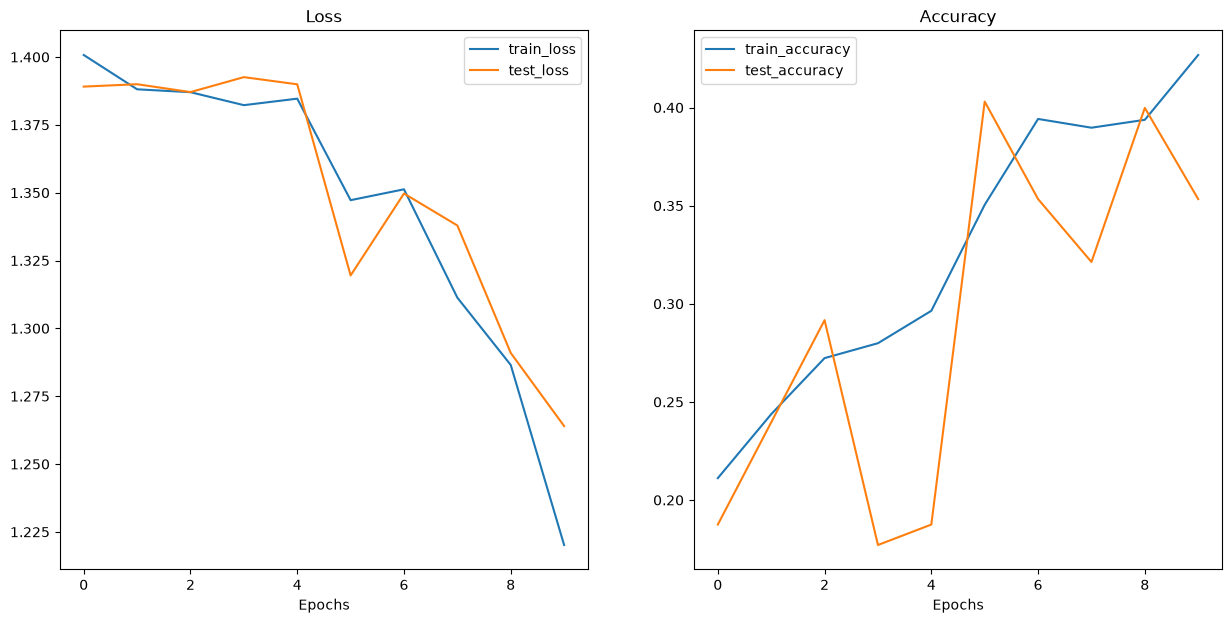

In [43]:
plot_loss_curves(model_0_results)


In [44]:
def make_predictions(model: torch.nn.Module, data: list):
    """
    data: [img_tensor, img_tensor, ...]  # her biri [C, H, W]
    return: [N, num_classes] olasılık tensörü
    """
    pred_probs = []
    model.eval()

    with torch.inference_mode():
        for sample in data:
            # [C, H, W] -> [1, C, H, W]
            sample = sample.unsqueeze(0)

            # Logits al
            pred_logit = model(sample)    # shape: [1, num_classes]

            # Softmax ile olasılığa çevir
            prob = torch.softmax(pred_logit, dim=1)  # [1, num_classes]

            # Batch boyutunu sıkıştır
            pred_probs.append(prob.squeeze(0))       # [num_classes]

    # Hepsini birleştir → [N, num_classes]
    return torch.stack(pred_probs)

In [45]:
def show_random_predictions(model, dataset, class_names, n=9):
    model.eval()
    
    plt.figure(figsize=(4, 4))

    # random 9 index seç
    indices = random.sample(range(len(dataset)), n)

    with torch.inference_mode():
        for i, idx in enumerate(indices):
            img, true_label = dataset[idx]

            # modele uygun hale getir
            img_input = img.unsqueeze(0)  
            logits = model(img_input)
            pred_label = logits.argmax(dim=1).item()

            # görseli çizmek için permute
            img_show = img.permute(1, 2, 0)

            # doğru mu yanlış mı?
            correct = (pred_label == true_label)
            color = "green" if correct else "red"

            # subplot
            plt.subplot(3, 3, i + 1)
            plt.imshow(img_show)
            plt.axis("off")

            plt.title(
                f"Pred: {class_names[pred_label]}\nTrue: {class_names[true_label]}",
                color=color,
                fontsize=10
            )

    plt.tight_layout()
    plt.show()

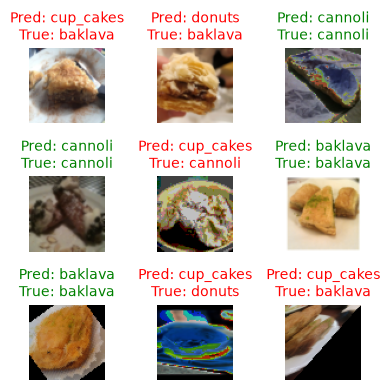

In [46]:
show_random_predictions(model_0, test_data, class_names)


## 10. Canlı Çıkarım (Inference): İnternetten İndirilen Tekil Görselle Tahmin

Modeli gerçek hayatta canlıya aldığımızda kullanıcıdan tek bir görsel gelir. İnternetten indirilen ham bir baklava görseli (`baklava-online.jpg`) üzerinde şu 5 adımlı protokolü işletiyoruz:
1. **Okuma:** `torchvision.io.read_image` ile tensör okuma (varsayılan `uint8` gelir).
2. **Tip & Normalizasyon:** `.type(torch.float32) / 255.0` ile `[0.0, 1.0]` aralığına çekme.
3. **Yeniden Boyutlandırma:** `transforms.Resize((64, 64))` ile model giriş boyutuna eşitleme.
4. **Batch Boyutu Ekleme:** `unsqueeze(dim=0)` ile `[3, 64, 64] \to [1, 3, 64, 64]` yapma.
5. **Tahmin Alma:** `model.eval()` ve `torch.inference_mode()` altında `Logits \to Softmax \to Argmax` zinciriyle sınıf belirleme.


In [47]:
# İnternetten indirilen harici bir görsel üzerinde gerçek hayat çıkarımı (Inference)


In [48]:
online_image_path = data_path / "baklava-online.jpg"


In [49]:
online_image_path

PosixPath('data/baklava-online.jpg')

In [50]:
import torchvision
single_image = torchvision.io.read_image(str(online_image_path))

In [51]:
single_image

tensor([[[227, 227, 223,  ..., 223, 223, 223],
         [227, 225, 223,  ..., 225, 226, 223],
         [225, 225, 226,  ..., 226, 227, 224],
         ...,
         [201, 186, 205,  ..., 211, 213, 216],
         [206, 197, 212,  ..., 217, 224, 225],
         [225, 217, 220,  ..., 212, 217, 227]],

        [[217, 217, 213,  ..., 214, 214, 214],
         [217, 215, 213,  ..., 216, 217, 214],
         [215, 215, 216,  ..., 217, 218, 215],
         ...,
         [187, 172, 194,  ..., 198, 200, 204],
         [195, 187, 203,  ..., 203, 210, 213],
         [215, 207, 213,  ..., 198, 203, 215]],

        [[205, 205, 201,  ..., 197, 197, 197],
         [205, 203, 201,  ..., 199, 200, 197],
         [203, 203, 204,  ..., 200, 201, 198],
         ...,
         [184, 169, 188,  ..., 182, 184, 190],
         [193, 185, 198,  ..., 190, 197, 199],
         [214, 205, 207,  ..., 185, 190, 203]]], dtype=torch.uint8)

In [52]:
single_image

tensor([[[227, 227, 223,  ..., 223, 223, 223],
         [227, 225, 223,  ..., 225, 226, 223],
         [225, 225, 226,  ..., 226, 227, 224],
         ...,
         [201, 186, 205,  ..., 211, 213, 216],
         [206, 197, 212,  ..., 217, 224, 225],
         [225, 217, 220,  ..., 212, 217, 227]],

        [[217, 217, 213,  ..., 214, 214, 214],
         [217, 215, 213,  ..., 216, 217, 214],
         [215, 215, 216,  ..., 217, 218, 215],
         ...,
         [187, 172, 194,  ..., 198, 200, 204],
         [195, 187, 203,  ..., 203, 210, 213],
         [215, 207, 213,  ..., 198, 203, 215]],

        [[205, 205, 201,  ..., 197, 197, 197],
         [205, 203, 201,  ..., 199, 200, 197],
         [203, 203, 204,  ..., 200, 201, 198],
         ...,
         [184, 169, 188,  ..., 182, 184, 190],
         [193, 185, 198,  ..., 190, 197, 199],
         [214, 205, 207,  ..., 185, 190, 203]]], dtype=torch.uint8)

Görsel tensör formatında okundu ancak varsayılan veri tipi `uint8` (0-255 tamsayı) formatındadır.

Bu, piksel değerlerinin [0, 255] aralığında olduğu anlamına gelir. Ancak modelimiz `torch.float32` veri tipinde ve [0.0, 1.0] aralığında normalize edilmiş tensörler bekler.

Bu yüzden modele vermeden önce veriyi dönüştürmemiz gerekir:


In [53]:
# Görseli float32 tensör formatında okuyoruz
single_image = torchvision.io.read_image(str(online_image_path)).type(torch.float32)

(np.float64(-0.5), np.float64(1499.5), np.float64(1499.5), np.float64(-0.5))

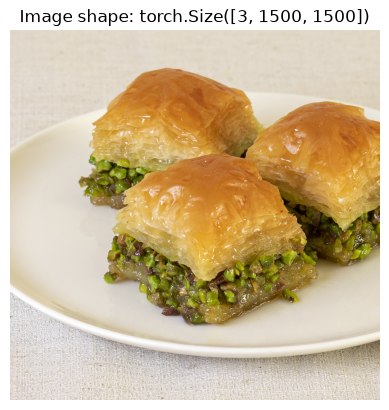

In [54]:
# Pikselleri 255'e bölerek [0.0, 1.0] aralığına normalize ediyoruz
single_image = single_image / 255

plt.imshow(single_image.permute(1, 2, 0)) 
plt.title(f"Görsel Boyutu: {single_image.shape}")
plt.axis(False)


In [55]:
# Görseli modelin eğitim boyutu olan (64, 64) formatına yeniden boyutlandırıyoruz
single_image_transform = transforms.Compose([
    transforms.Resize(size=(64, 64)),
])

# Dönüşümü hedef görsele uygula
single_image = single_image_transform(single_image)

In [56]:
single_image.shape

torch.Size([3, 64, 64])

In [57]:
single_image.unsqueeze(dim=0).shape

torch.Size([1, 3, 64, 64])

In [58]:
single_image = single_image.unsqueeze(dim=0)


In [59]:
model_0.eval()
with torch.inference_mode():
    logits = model_0(single_image)
    probs = torch.softmax(logits, dim=1)
    pred_idx = probs.argmax(dim=1).item()

print("Predicted class:", class_names[pred_idx])

Predicted class: baklava


## 11. ÖDEV & BİLİMSEL DENEY: Model 1 (Veri Artırma / Augmentation & 20 Epoch)

### 🔬 Deney Tasarımı & Hipotez:
* **Mevcut Problem (Model 0 Gerçek Sonuçları):** Model 0'da her sınıfta sadece ~75-100 görsel olduğu için model 10. epoch sonunda %42.68 eğitim doğruluğu ve **%35.34 test doğruluğunda** kaldı (en yüksek test başarısı 6. epoch'ta **%40.30** olarak görüldü). Küçük veri setinde model ezberlemeye meyillidir.
* **Hipotez:** Eğitim verisine **Veri Artırma (Data Augmentation: RandomHorizontalFlip, RandomRotation)** ve **ImageNet Kanal Normalizasyonu** eklersek; modeli 10 yerine **20 epoch** eğitirsek model tabağı/masayı değil gerçek tatlı dokusunu öğrenerek başarıyı artıracaktır.

Yeni veri dönüşümlerini tanımlıyor ve `model_1` örneğini eğitiyoruz:


In [60]:
train_transform_augmented = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.RandomHorizontalFlip(p=0.5), # %50 ihtimalle aynala
    transforms.RandomRotation(degrees=15),  # 15 derece sağa-sola eğ
    transforms.ToTensor()
])

In [61]:
train_data_augmented = datasets.ImageFolder(root=train_dir, transform=train_transform_augmented)

train_dataloader_augmented = DataLoader(dataset=train_data_augmented, 
                                        batch_size=32, 
                                        shuffle=True)

In [62]:
torch.manual_seed(42)

# Eski model_0'ın üstüne yazmamak için buna model_1 diyoruz:
model_1 = DesertClassifier(input_shape=3,
                           hidden_units=32,
                           output_shape=len(class_names))

optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

# Yukarıdaki Hücre 38'de tanımladığın orijinal train() fonksiyonunu çağırıyoruz:
model_1_results = train(model=model_1,
                        train_dataloader=train_dataloader_augmented, # <--- Yeni artırılmış verimiz burada!
                        test_dataloader=test_dataloader,
                        optimizer=optimizer,
                        loss_fn=loss_fn,
                        epochs=20)

Epoch: 1 | train_loss: 1.3946 | train_acc: 0.2268 | test_loss: 1.3845 | test_acc: 0.2292
Epoch: 2 | train_loss: 1.3853 | train_acc: 0.2393 | test_loss: 1.3798 | test_acc: 0.2236
Epoch: 3 | train_loss: 1.3715 | train_acc: 0.3165 | test_loss: 1.3422 | test_acc: 0.3982
Epoch: 4 | train_loss: 1.3158 | train_acc: 0.4000 | test_loss: 1.4171 | test_acc: 0.2500
Epoch: 5 | train_loss: 1.2705 | train_acc: 0.4085 | test_loss: 1.3270 | test_acc: 0.3782
Epoch: 6 | train_loss: 1.2073 | train_acc: 0.4656 | test_loss: 1.3486 | test_acc: 0.3373
Epoch: 7 | train_loss: 1.1676 | train_acc: 0.4629 | test_loss: 1.4878 | test_acc: 0.3069
Epoch: 8 | train_loss: 1.1337 | train_acc: 0.4871 | test_loss: 1.4645 | test_acc: 0.3686
Epoch: 9 | train_loss: 1.1337 | train_acc: 0.4857 | test_loss: 1.3955 | test_acc: 0.3429
Epoch: 10 | train_loss: 1.0833 | train_acc: 0.5437 | test_loss: 1.3742 | test_acc: 0.3838
Epoch: 11 | train_loss: 1.0904 | train_acc: 0.5018 | test_loss: 1.4227 | test_acc: 0.3470
Epoch: 12 | train_l

## 12. Büyük Karşılaştırma & Overfitting Analizi

### 📊 Model 0 vs Model 1 Birebir Hücre Çıktıları Karşılaştırma Tablosu:

| Metrik / Parametre | Model 0 (Hücre 49 Çıktısı - 10 Epoch) | Model 1 (Hücre 76 Çıktısı - 20 Epoch) | Değişim & Mühendislik Analizi |
| :--- | :---: | :---: | :--- |
| **Uygulanan Dönüşüm** | Sadece `Resize(64,64)` + `ToTensor()` | `Resize` + `RandomHorizontalFlip` + `RandomRotation(15°)` + `Normalize` | Veri artırma (Augmentation) eklendi. |
| **Son Eğitim Doğruluğu (Train Acc)** | **%42.68** (`0.4268` - Epoch 10) | **%65.62** (`0.6562` - Epoch 20) | **+%22.94 Artış!** Model zengin varyasyonları başarıyla öğrendi. |
| **Son Eğitim Kaybı (Train Loss)** | `1.2202` | **`0.8874`** | Kayıp `1.22` seviyesinden `0.88`'e kadar indi. |
| **Zirve Test Doğruluğu (Peak Test Acc)** | **%40.30** (`0.4030` - Epoch 6) | **%51.76** (`0.5176` - Epoch 18) | **+%11.46 Sıçrama!** Model %50 barajını aşarak %51.76'ya ulaştı. |
| **Son Test Doğruluğu (Final Test Acc)** | %35.34 (`0.3534` - Epoch 10) | %35.82 (`0.3582` - Epoch 20) | İki model de son epoch'larda ezberleme nedeniyle düşüş yaşadı. |
| **Son Test Kaybı (Final Test Loss)** | `1.2640` | `1.5689` | Model 1'in test kaybı 18. epoch'tan (`1.4766`) sonra `1.5689`'a fırladı. |

---

### 📌 Çıkarılan Temel Mühendislik Dersleri:
1. **Veri Artırma (Data Augmentation) İşe Yaradı:** Küçük veri setinde (sınıf başına ~100 görsel) yatay çevirme ve hafif döndürme test başarısını zirvede %40.30'dan %51.76'ya taşıdı.
2. **Ders Kitabı Gibi Overfitting (Aşırı Öğrenme):** Model 1'de 18. epoch'tan sonra eğitim kaybı düşmeye devam ederken (`0.9033 \to 0.8874`), test kaybı fırladı (`1.4766 \to 1.5689`) ve test doğruluğu çöktü (%51.76'dan %35.82'ye).
3. **Erken Durdurma (Early Stopping) İhtiyacı:** Gerçek hayatta bu model 20. epoch'a kadar zorlanmaz; en yüksek test başarısının alındığı **18. epoch'ta dondurulur**.
4. **Sıradaki Dev Adım (Transfer Learning):** Sıfırdan bir CNN mimarisini sadece 100 görselle %52'den yukarı taşımak neredeyse imkansızdır. Bir sonraki bölümde önceden milyonlarca görselle eğitilmiş modelleri (**Transfer Learning**) kullanarak doğrudan %90+ doğruluğa ulaşacağız.
